# RQ1
**Question**: How do cardiovascular, psychiatric, and dependence-related adverse event reporting patterns differ between stimulant and nonstimulant medications, and how do these patterns vary by patient age and sex?

## Research Objective
The objective of the analysis is to examine how cardiovascular, psychiatric, and dependence-related adverse event reporting patterns differ between simulant and nonstimulant ADHD medications. The analysis also considers patient age and sexto identify how these reporting patterns vary across demographic groups.

We will examine these relationships using using logistic regression, decision trees, and support vector machines and compare classification performance. The goal is to identify meaningful patterns within the FAERS dataset rather than predict the clinical risk of adverse events.

## Data
**Source**:  Capstone_faers_adhd_data_only

## Predictors
Three independent variables were selected for the analysis:
* **rq1_group**: Medication classification (STIMULANT and NONSTIMULANT)
* **age_band_fine**: Range of age groups among patients (0–5, 6–11, 12–17, 18–25, 26–44, 45–64, and 65_PLUS, or unknown)
* **sex_category**: Patient sex (M and F, or unknown)

These variables were chosen to examine difference in adverse event reporting patterns between stimulant and nonstimulant ADHD medications and cross demagraphic groups.

## Missing Data
* **Patient Age**: Approximately 49.4% of cases contained missing age information.
* **Patient Sex**: Approximately 22.7% of cases contained missing or unspecified sex information.

Cases with missing demographic information may introduce bias and limit the interpretation of reporting patterns.

## Models
* **Logistic Regression**:  Statistical classification model that examines associations between mediction class, age, sex, and adverse event reporting.
* **Decision Tree**:  Machine learning model that divides cases into groups based on medication class and demographics to identify patterns and interactions associated with adverse event reporting.
* **Support Vector Machine**:  Machine learning model that uses a non linear decision boundary to distinguish cases with and without reported adverse events. Providing an alternative approach for comparing classification performance.

## Training and Testing
The dataset will be randomly divided into 60% training, 15% validation, and 25% testing. Due to the smaller proportion of related cases to dependence-related events, stratified sampling will be used to maintain the distribution of adverse event outcomes.

Logistic regression, decision tree, and support vector machine models will be trained seperately for cardiovascular. psychiatric, and dependence-related adverse event reporting. The validation datasets will be used to select model settings , while testing will serve as the final evaluation. All three methods will use the same data partitions.

## Evaluation
Model performance wiil be measured using accuracy, precision, recall, F1-score, and ROC-AUC. An average precision will also be included to calculate for class imbalance, particularly with dependence-related events. Because some adverse event categories occur less frequently, greater emphasis will be placed on precision, recall, F1-score, and average precision rather than accuracy alone.

The result will be compared across the three modeling techniques to identify differences in classification performance. Logistic regression coefficients and decision tree splits will also be examined to help interpret relationships between medication class, patient demographics, and adverse event reporting.

## Setup

In [ ]:
# Use for token input instead

#import os
#import duckdb

#import getpass
#os.environ["motherduck_token"] = getpass.getpass(
#"Paste your MotherDuck token: "
#)

In [ ]:
import os
import duckdb

# Remove any MotherDuck token from this Python process.
os.environ.pop("MOTHERDUCK_TOKEN", None)

# Connect using MotherDuck's browser authentication.
con = duckdb.connect("md:")

# Verify the connection.
print(con.sql("SELECT 1 AS test").df())

   test
0     1


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Connect to FAERS ADHD table
con = duckdb.connect('md:_share/Capstone_faers_adhd_data_only/6fc22063-9b4d-4a08-843a-a3bb9391d9d5')
con.sql("SELECT pipeline_version, built_at_utc FROM study_build").df()

,pipeline_version,built_at_utc
0,0.27.0,2026-11-03T20:36:19Z


In [ ]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    roc_auc_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

from scipy.stats import norm

import time

import seaborn as sns

from matplotlib.ticker import FixedLocator, FixedFormatter, NullFormatter

In [ ]:
rng = 42

#### Retrieve the data
The data was retrieved from the FAERS ADHD study dataset, selecting cases involving stimulant and nonstimulant medications. Patient age, sex, and the three adverse-event categories were included for the analysis.

In [ ]:
# Retrieve the data
query = """
SELECT
    caseid,
    rq1_group,
    age_band_fine,
    sex_category,
    cardiovascular_narrow,
    psychiatric_narrow,
    dependence_narrow
FROM adhd_cases
WHERE rq1_group IN ('STIMULANT', 'NONSTIMULANT')
"""

df = con.execute(query).df()

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (93803, 7)


,caseid,rq1_group,age_band_fine,sex_category,cardiovascular_narrow,psychiatric_narrow,dependence_narrow
0,10003669,STIMULANT,None,UNKNOWN,False,False,False
1,10004384,STIMULANT,None,M,True,True,False
2,10005897,NONSTIMULANT,18_25,F,False,True,False
3,10005899,STIMULANT,None,UNKNOWN,False,False,False
4,10006048,STIMULANT,12_17,M,False,False,False


#### Data with Missing/Unknown Values
The dataset was examined to verify the number of cases, identify missing values, and evaluate the distribution of each adverse-event category. This helped identify potential data limitations and class imbalances before model training.

In [ ]:
# Verify cthe cohort
print(df["rq1_group"].value_counts())

print("\nUnique cases:", df["caseid"].nunique())

print("\nMissing values:")
print(df.isna().sum())

rq1_group
STIMULANT       81998
NONSTIMULANT    11805
Name: count, dtype: int64

Unique cases: 93803

Missing values:
caseid                       0
rq1_group                    0
age_band_fine            46472
sex_category             19157
cardiovascular_narrow        0
psychiatric_narrow           0
dependence_narrow            0
dtype: int64


In [ ]:
# Examine adverse event distributions
targets = [
    "cardiovascular_narrow",
    "psychiatric_narrow",
    "dependence_narrow"
]

for target in targets:
    print(f"\n{target}")
    print(df[target].value_counts())
    print(df[target].value_counts(normalize=True).mul(100).round(2))

# Age and Sex categories
print("\nAge:")
print(df["age_band_fine"].value_counts(dropna=False))
print("\nSex:")
print(df["sex_category"].value_counts(dropna=False))


cardiovascular_narrow
cardiovascular_narrow
False    83784
True     10019
Name: count, dtype: int64
cardiovascular_narrow
False    89.32
True     10.68
Name: proportion, dtype: float64

psychiatric_narrow
psychiatric_narrow
False    72861
True     20942
Name: count, dtype: int64
psychiatric_narrow
False    77.67
True     22.33
Name: proportion, dtype: float64

dependence_narrow
dependence_narrow
False    92553
True      1250
Name: count, dtype: int64
dependence_narrow
False    98.67
True      1.33
Name: proportion, dtype: float64

Age:
age_band_fine
None       46472
26_44      14576
6_11       10088
12_17       7808
45_64       6657
18_25       5841
0_5         1310
65_PLUS     1051
Name: count, dtype: int64

Sex:
sex_category
M          38702
F          33817
None       19157
UNKNOWN     2127
Name: count, dtype: int64


#### Data Preperation
Missing patient age and sex values were assigned to an UNKNOWN category to retain these cases in the analysis. Medication class, age, and sex were then separated as predictor variables, with the three adverse-event categories used as target variables.

In [ ]:
# Handling the missing demographic values
df_copy = df.copy()

# Replace missing value demographics with UNKNOWN
df_copy["age_band_fine"] = (df_copy["age_band_fine"].fillna("UNKNOWN"))
df_copy["sex_category"] = (df_copy["sex_category"].fillna("UNKNOWN"))

# Verify
print("Age:")
print(df_copy["age_band_fine"].value_counts(dropna=False))
print("\nSex:")
print(df_copy["sex_category"].value_counts(dropna=False))

# Check for ramaining missing values
print("\nRemaining missing values:")
print(df_copy.isna().sum())

Age:
age_band_fine
UNKNOWN    46472
26_44      14576
6_11       10088
12_17       7808
45_64       6657
18_25       5841
0_5         1310
65_PLUS     1051
Name: count, dtype: int64

Sex:
sex_category
M          38702
F          33817
UNKNOWN    21284
Name: count, dtype: int64

Remaining missing values:
caseid                   0
rq1_group                0
age_band_fine            0
sex_category             0
cardiovascular_narrow    0
psychiatric_narrow       0
dependence_narrow        0
dtype: int64


In [ ]:
#Seperate the predictors from target variables
predictors = ["rq1_group", "age_band_fine", "sex_category"]

X = df_copy[predictors].copy()

targets = ["cardiovascular_narrow", "psychiatric_narrow", "dependence_narrow"]

y = df_copy[targets].copy()

# Verify datasets
print("Predictors:", X.shape)
print("Targets:", y.shape)

display(X.head())
display(y.head())

Predictors: (93803, 3)
Targets: (93803, 3)


,rq1_group,age_band_fine,sex_category
0,STIMULANT,UNKNOWN,UNKNOWN
1,STIMULANT,UNKNOWN,M
2,NONSTIMULANT,18_25,F
3,STIMULANT,UNKNOWN,UNKNOWN
4,STIMULANT,12_17,M


,cardiovascular_narrow,psychiatric_narrow,dependence_narrow
0,False,False,False
1,True,True,False
2,False,True,False
3,False,False,False
4,False,False,False


#### Data Encoding
One-hot encoding was used to convert medication class, age, and sex into numerical features for the machine learning models.

In [ ]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)


#### Train/Test/Validation Split
The dataset was divided into 60% training, 15% validation, and 25% testing. The training set was used to fit the models, the validation set was used to compare their performance, and the testing set was reserved for final evaluation.

In [ ]:
# Training, Validation, and Testing sets
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.25, random_state=rng, stratify=y["dependence_narrow"])
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.2, random_state=rng, stratify=y_temp["dependence_narrow"])

# Verify
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (56281, 3)
Validation: (14071, 3)
Testing: (23451, 3)


In [ ]:
# Fit the encoder and transform the data
X_train_encoded = encoder.fit_transform(X_train)

X_val_encoded = encoder.transform(X_val)
X_test_encoded = encoder.transform(X_test)

# Verify
print("Training:", X_train_encoded.shape)
print("Validation:", X_val_encoded.shape)
print("Testing:", X_test_encoded.shape)

Training: (56281, 13)
Validation: (14071, 13)
Testing: (23451, 13)


#### Encoder Feature Verification
The encoded feature names were displayed to verify that the categorical predictors were converted correctly. This also provided the number of features used during model training.

In [ ]:
# Display the new feature names
feature_names = encoder.get_feature_names_out(X_train.columns)

print("Number of encoded features:", len(feature_names))
print("\nEncoded feature names:")
print(feature_names)

Number of encoded features: 13

Encoded feature names:
['rq1_group_NONSTIMULANT' 'rq1_group_STIMULANT' 'age_band_fine_0_5'
 'age_band_fine_12_17' 'age_band_fine_18_25' 'age_band_fine_26_44'
 'age_band_fine_45_64' 'age_band_fine_65_PLUS' 'age_band_fine_6_11'
 'age_band_fine_UNKNOWN' 'sex_category_F' 'sex_category_M'
 'sex_category_UNKNOWN']


#### Logistic Regression Model Training
Logistic Regression models were trained separately for cardiovascular, psychiatric, and dependence-related adverse-event reporting. Class weighting was applied to account for the imbalance between positive and negative outcomes.

In [ ]:
lr_models = {}

for target in ["cardiovascular_narrow", "psychiatric_narrow", "dependence_narrow"]:

    model = LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=rng
    )

    model.fit(X_train_encoded, y_train[target])

    predictions = model.predict(X_val_encoded)
    probabilities = model.predict_proba(X_val_encoded)[:, 1]

    lr_models[target] = model

    print(f"\n--- {target} ---")
    print(classification_report(
        y_val[target],
        predictions,
        zero_division=0
    ))

    print("ROC-AUC:", round(
        roc_auc_score(y_val[target], probabilities), 4
    ))

    print("Average Precision:", round(
        average_precision_score(y_val[target], probabilities), 4
    ))


--- cardiovascular_narrow ---
              precision    recall  f1-score   support

       False       0.93      0.63      0.75     12555
        True       0.17      0.62      0.27      1516

    accuracy                           0.63     14071
   macro avg       0.55      0.63      0.51     14071
weighted avg       0.85      0.63      0.70     14071

ROC-AUC: 0.6593
Average Precision: 0.166

--- psychiatric_narrow ---
              precision    recall  f1-score   support

       False       0.83      0.61      0.70     10898
        True       0.30      0.57      0.39      3173

    accuracy                           0.60     14071
   macro avg       0.56      0.59      0.55     14071
weighted avg       0.71      0.60      0.63     14071

ROC-AUC: 0.6135
Average Precision: 0.3034

--- dependence_narrow ---
              precision    recall  f1-score   support

       False       0.99      0.67      0.80     13884
        True       0.03      0.66      0.05       187

    accuracy 

#### Decision Tree Model Training
Decision Tree models were trained for each adverse-event category using class weighting and restrictions on tree depth and minimum leaf size. These settings were used to limit model complexity while accounting for class imbalance.

In [ ]:
dt_models = {}

for target in targets:

    model = DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=50,
        class_weight="balanced",
        random_state=rng
    )

    model.fit(X_train_encoded, y_train[target])

    predictions = model.predict(X_val_encoded)
    probabilities = model.predict_proba(X_val_encoded)[:, 1]

    dt_models[target] = model

    print(f"\n--- {target} ---")

    print(classification_report(
        y_val[target],
        predictions,
        zero_division=0
    ))

    print("ROC-AUC:", round(
        roc_auc_score(y_val[target], probabilities), 4
    ))

    print("Average Precision:", round(
        average_precision_score(y_val[target], probabilities), 4
    ))


--- cardiovascular_narrow ---
              precision    recall  f1-score   support

       False       0.94      0.62      0.75     12555
        True       0.17      0.65      0.27      1516

    accuracy                           0.62     14071
   macro avg       0.55      0.63      0.51     14071
weighted avg       0.85      0.62      0.70     14071

ROC-AUC: 0.6595
Average Precision: 0.1642

--- psychiatric_narrow ---
              precision    recall  f1-score   support

       False       0.83      0.62      0.71     10898
        True       0.30      0.56      0.39      3173

    accuracy                           0.61     14071
   macro avg       0.56      0.59      0.55     14071
weighted avg       0.71      0.61      0.64     14071

ROC-AUC: 0.6128
Average Precision: 0.3013

--- dependence_narrow ---
              precision    recall  f1-score   support

       False       0.99      0.75      0.85     13884
        True       0.03      0.54      0.05       187

    accuracy

#### Support Vector Machine Model Training
Support Vector Machine (SVM) models were trained using an RBF kernel and class weighting. Their performance was evaluated alongside Logistic Regression and Decision Tree to compare different classification approaches.

In [ ]:
svm_models = {}

for target in targets:

    model = SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced",
        cache_size=1000,
        random_state=rng
    )

    start_time = time.perf_counter()

    model.fit(X_train_encoded, y_train[target])

    training_time = time.perf_counter() - start_time

    predictions = model.predict(X_val_encoded)
    scores = model.decision_function(X_val_encoded)

    svm_models[target] = model

    print(f"\n--- {target} ---")
    print(f"Training time: {training_time:.2f} seconds")

    print(classification_report(
        y_val[target],
        predictions,
        zero_division=0
    ))

    print("ROC-AUC:", round(
        roc_auc_score(y_val[target], scores), 4
    ))

    print("Average Precision:", round(
        average_precision_score(y_val[target], scores), 4
    ))


--- cardiovascular_narrow ---
Training time: 40.45 seconds
              precision    recall  f1-score   support

       False       0.94      0.62      0.75     12555
        True       0.17      0.64      0.27      1516

    accuracy                           0.63     14071
   macro avg       0.55      0.63      0.51     14071
weighted avg       0.85      0.63      0.70     14071

ROC-AUC: 0.635
Average Precision: 0.1616

--- psychiatric_narrow ---
Training time: 47.44 seconds
              precision    recall  f1-score   support

       False       0.83      0.63      0.72     10898
        True       0.30      0.56      0.39      3173

    accuracy                           0.61     14071
   macro avg       0.57      0.59      0.55     14071
weighted avg       0.71      0.61      0.64     14071

ROC-AUC: 0.6014
Average Precision: 0.2928

--- dependence_narrow ---
Training time: 36.45 seconds
              precision    recall  f1-score   support

       False       0.99      0.62  

In [ ]:
# Compare logistic regression class weighting
for target in targets:

    print(f"\n--- {target} ---")

    for weight in [None, "balanced"]:

        model = LogisticRegression(
            max_iter=1000,
            class_weight=weight,
            random_state=42
        )

        model.fit(X_train_encoded, y_train[target])

        predictions = model.predict(X_val_encoded)
        probabilities = model.predict_proba(X_val_encoded)[:, 1]

        print(f"\nClass weight: {weight}")
        print("Precision:", round(
            precision_score(y_val[target], predictions, zero_division=0), 4
        ))
        print("Recall:", round(
            recall_score(y_val[target], predictions, zero_division=0), 4
        ))
        print("F1:", round(
            f1_score(y_val[target], predictions, zero_division=0), 4
        ))
        print("ROC-AUC:", round(
            roc_auc_score(y_val[target], probabilities), 4
        ))
        print("Average Precision:", round(
            average_precision_score(y_val[target], probabilities), 4
        ))


--- cardiovascular_narrow ---

Class weight: None
Precision: 0.0
Recall: 0.0
F1: 0.0
ROC-AUC: 0.6597
Average Precision: 0.1676

Class weight: balanced
Precision: 0.1688
Recall: 0.622
F1: 0.2655
ROC-AUC: 0.6593
Average Precision: 0.166

--- psychiatric_narrow ---

Class weight: None
Precision: 0.0
Recall: 0.0
F1: 0.0
ROC-AUC: 0.6137
Average Precision: 0.3039

Class weight: balanced
Precision: 0.2968
Recall: 0.5701
F1: 0.3904
ROC-AUC: 0.6135
Average Precision: 0.3034

--- dependence_narrow ---

Class weight: None
Precision: 0.0
Recall: 0.0
F1: 0.0
ROC-AUC: 0.7263
Average Precision: 0.0317

Class weight: balanced
Precision: 0.0262
Recall: 0.6631
F1: 0.0504
ROC-AUC: 0.7303
Average Precision: 0.0319


#### Model Validation
The three machine learning algorithms were evaluated on the validation dataset across all three adverse-event categories. Average Precision was used as the primary comparison metric to select the best-performing model for each outcome.

In [ ]:
# Collect validation metrics for all nine models
results = []

model_groups = {
    "Logistic Regression": lr_models,
    "Decision Tree": dt_models,
    "SVM": svm_models
}

for model_name, models in model_groups.items():
    for target in targets:

        model = models[target]
        predictions = model.predict(X_val_encoded)

        # SVM uses decision scores; other models use probabilities
        if model_name == "SVM":
            scores = model.decision_function(X_val_encoded)
        else:
            scores = model.predict_proba(X_val_encoded)[:, 1]

        results.append({
            "Model": model_name,
            "Outcome": target,
            "Precision": precision_score(y_val[target], predictions, zero_division=0),
            "Recall": recall_score(y_val[target], predictions, zero_division=0),
            "F1": f1_score(y_val[target], predictions, zero_division=0),
            "ROC-AUC": roc_auc_score(y_val[target], scores),
            "Average Precision": average_precision_score(y_val[target], scores)
        })

validation_results = pd.DataFrame(results)

display(validation_results.round(4))

,Model,Outcome,Precision,Recall,F1,ROC-AUC,Average Precision
0,Logistic Regression,cardiovascular_narrow,0.1688,0.6220,0.2655,0.6593,0.1660
1,Logistic Regression,psychiatric_narrow,0.2968,0.5701,0.3904,0.6135,0.3034
2,Logistic Regression,dependence_narrow,0.0262,0.6631,0.0504,0.7303,0.0319
3,Decision Tree,cardiovascular_narrow,0.1711,0.6484,0.2708,0.6595,0.1642
4,Decision Tree,psychiatric_narrow,0.2996,0.5610,0.3906,0.6128,0.3013
5,Decision Tree,dependence_narrow,0.0282,0.5401,0.0537,0.7076,0.0286
6,SVM,cardiovascular_narrow,0.1715,0.6438,0.2709,0.6350,0.1616
7,SVM,psychiatric_narrow,0.3034,0.5553,0.3924,0.6014,0.2928
8,SVM,dependence_narrow,0.0235,0.6845,0.0455,0.6625,0.0256


#### Final Model Evaluation
The trained models were evaluated using the testing dataset to measure their performance on previously unseen data. Accuracy, precision, recall, F1-score, ROC-AUC, and Average Precision were calculated for each adverse-event category.

In [ ]:
# Store final test results
test_results = []

for model_name, models in model_groups.items():
    for target in targets:

        model = models[target]

        # Generate predictions using the untouched test dataset
        predictions = model.predict(X_test_encoded)

        # Obtain scores for ranking metrics
        if model_name == "SVM":
            scores = model.decision_function(X_test_encoded)
        else:
            scores = model.predict_proba(X_test_encoded)[:, 1]

        # Record performance metrics
        test_results.append({
            "Model": model_name,
            "Outcome": target,
            "Accuracy": accuracy_score(y_test[target], predictions),
            "Precision": precision_score(
                y_test[target], predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test[target], predictions, zero_division=0
            ),
            "F1": f1_score(
                y_test[target], predictions, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(y_test[target], scores),
            "Average Precision": average_precision_score(
                y_test[target], scores
            )
        })

# Create final evaluation table
test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))

,Model,Outcome,Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision
0,Logistic Regression,cardiovascular_narrow,0.6282,0.1663,0.6175,0.2621,0.6462,0.1585
1,Logistic Regression,psychiatric_narrow,0.5887,0.2834,0.5568,0.3756,0.5983,0.2812
2,Logistic Regression,dependence_narrow,0.6610,0.0242,0.6198,0.0465,0.7020,0.0280
3,Decision Tree,cardiovascular_narrow,0.6221,0.1666,0.6334,0.2638,0.6477,0.1581
4,Decision Tree,psychiatric_narrow,0.5975,0.2870,0.5468,0.3764,0.5985,0.2834
5,Decision Tree,dependence_narrow,0.7426,0.0273,0.5272,0.0518,0.6951,0.0263
6,SVM,cardiovascular_narrow,0.6247,0.1669,0.6290,0.2638,0.6211,0.1474
7,SVM,psychiatric_narrow,0.6027,0.2888,0.5392,0.3761,0.5947,0.2776
8,SVM,dependence_narrow,0.6146,0.0227,0.6613,0.0438,0.6497,0.0233


#### Reporting Patterns by Age Group
Reporting percentages were calculated across patient age groups for both stimulant and nonstimulant medications. The results showed differences in reporting patterns across age categories, particularly for psychiatric and dependence-related adverse events.

In [ ]:
# Calculate adverse-event reporting proportions by medication class
reporting_rates = (
    df_copy
    .groupby("rq1_group")[targets]
    .mean()
    .mul(100)
    .round(2)
)

# Count cases in each medication group
group_counts = df_copy["rq1_group"].value_counts()

print("Cases by medication class:")
print(group_counts)

print("\nAdverse-event reporting percentages:")
display(reporting_rates)

Cases by medication class:
rq1_group
STIMULANT       81998
NONSTIMULANT    11805
Name: count, dtype: int64

Adverse-event reporting percentages:


,cardiovascular_narrow,psychiatric_narrow,dependence_narrow
rq1_group,,,
NONSTIMULANT,14.60,26.90,0.31
STIMULANT,10.12,21.67,1.48


In [ ]:
# Calculate reporting percentages by medication class and age
age_reporting_rates = (
    df_copy
    .groupby(["age_band_fine", "rq1_group"])[targets]
    .mean()
    .mul(100)
    .round(2)
)

# Count cases in each age and medication group
age_group_counts = (
    df_copy
    .groupby(["age_band_fine", "rq1_group"])
    .size()
    .rename("Case Count")
)

# Combine group sizes and reporting percentages
age_results = pd.concat(
    [age_group_counts, age_reporting_rates],
    axis=1
)

display(age_results)

Case Count  cardiovascular_narrow  \
age_band_fine rq1_group                                         
0_5           NONSTIMULANT         196                  10.71   
              STIMULANT           1114                   9.43   
12_17         NONSTIMULANT        1598                  17.71   
              STIMULANT           6210                  12.87   
18_25         NONSTIMULANT         844                  20.97   
              STIMULANT           4997                  17.81   
26_44         NONSTIMULANT        1632                  18.44   
              STIMULANT          12944                  17.69   
45_64         NONSTIMULANT         694                  22.62   
              STIMULANT           5963                  16.92   
65_PLUS       NONSTIMULANT         129                  22.48   
              STIMULANT            922                  15.73   
6_11          NONSTIMULANT        2162                  10.64   
              STIMULANT           7926                   4.57   
UNKNOWN       NONSTIMULANT        4550                  11.56   
              STIMULANT          41922                   6.43   

                            psychiatric_narrow  dependence_narrow  
age_band_fine rq1_group                                            
0_5           NONSTIMULANT               25.00               0.00  
              STIMULANT                  17.06               0.81  
12_17         NONSTIMULANT               30.79               0.00  
              STIMULANT                  31.59               0.63  
18_25         NONSTIMULANT               35.55               1.42  
              STIMULANT                  30.94               2.18  
26_44         NONSTIMULANT               32.72               0.37  
              STIMULANT                  28.09               2.87  
45_64         NONSTIMULANT               28.67               0.43  
              STIMULANT                  27.08               1.39  
65_PLUS       NONSTIMULANT               19.38               0.00  
              STIMULANT                  27.22               0.76  
6_11          NONSTIMULANT               28.77               0.05  
              STIMULANT                  19.59               0.21  
UNKNOWN       NONSTIMULANT               20.99               0.33  
              STIMULANT                  16.73               1.38

#### Reporting Patterns by Sex
Adverse-event reporting percentages were compared between male and female patients within each medication class. Both groups showed higher dependence-related reporting percentages for stimulants, while cardiovascular and psychiatric reporting percentages were lower compared with nonstimulants.

In [ ]:
# Calculate reporting percentages by medication class and sex
sex_reporting_rates = (
    df_copy
    .groupby(["sex_category", "rq1_group"])[targets]
    .mean()
    .mul(100)
    .round(2)
)

# Count cases in each sex and medication group
sex_group_counts = (
    df_copy
    .groupby(["sex_category", "rq1_group"])
    .size()
    .rename("Case Count")
)

# Combine case counts and reporting percentages
sex_results = pd.concat(
    [sex_group_counts, sex_reporting_rates],
    axis=1
)

display(sex_results)

Case Count  cardiovascular_narrow  \
sex_category rq1_group                                         
F            NONSTIMULANT        4100                  17.12   
             STIMULANT          29717                  12.72   
M            NONSTIMULANT        5841                  12.43   
             STIMULANT          32861                  10.11   
UNKNOWN      NONSTIMULANT        1864                  15.88   
             STIMULANT          19420                   6.14   

                           psychiatric_narrow  dependence_narrow  
sex_category rq1_group                                            
F            NONSTIMULANT               28.10               0.24  
             STIMULANT                  25.89               1.12  
M            NONSTIMULANT               28.68               0.36  
             STIMULANT                  21.74               2.17  
UNKNOWN      NONSTIMULANT               18.72               0.32  
             STIMULANT                  15.07               0.85

#### Reference Categories for Adjusted Logistic Regression
Reference categories were established for the adjusted logistic regression analysis, using nonstimulant medications, patients aged 18-25, and female patients as the comparison groups. These reference categories allow the odds ratios to be interpreted consistently across the three adverse-event outcomes.

In [ ]:
# Specify reference categories for interpretation
interpret_encoder = OneHotEncoder(
    categories=[
        ["NONSTIMULANT", "STIMULANT"],
        ["18_25", "0_5", "6_11", "12_17",
         "26_44", "45_64", "65_PLUS", "UNKNOWN"],
        ["F", "M", "UNKNOWN"]
    ],
    drop="first",
    handle_unknown="ignore",
    sparse_output=False
)

# Fit only on the training data
X_train_interpret = interpret_encoder.fit_transform(X_train)

# Retrieve feature names
interpret_features = interpret_encoder.get_feature_names_out(
    X_train.columns
)

print(interpret_features)

['rq1_group_STIMULANT' 'age_band_fine_0_5' 'age_band_fine_6_11'
 'age_band_fine_12_17' 'age_band_fine_26_44' 'age_band_fine_45_64'
 'age_band_fine_65_PLUS' 'age_band_fine_UNKNOWN' 'sex_category_M'
 'sex_category_UNKNOWN']


#### Adjusted Logistic Regression and Odds Ratios
Adjusted logistic regression models were fitted separately for cardiovascular, psychiatric, and dependence-related adverse-event reporting. Odds ratios, 95% confidence intervals, and p-values were calculated to examine the associations between medication class, patient demographics, and adverse-event reporting.

In [ ]:
# Store the logistic regression models and results
interpret_models = {}
odds_ratio_results = {}

for target in targets:

    # Fit an unweighted logistic regression model
    model = LogisticRegression(
        penalty=None,
        max_iter=2000
    )

    model.fit(X_train_interpret, y_train[target].astype(int))
    interpret_models[target] = model

    # Calculate predicted probabilities
    probabilities = model.predict_proba(X_train_interpret)[:, 1]

    # Add an intercept column for statistical calculations
    X_design = np.column_stack([
        np.ones(len(X_train_interpret)),
        X_train_interpret
    ])

    # Calculate the information matrix
    weights = probabilities * (1 - probabilities)
    information = X_design.T @ (X_design * weights[:, None])

    # Estimate standard errors from the covariance matrix
    covariance = np.linalg.inv(information)
    standard_errors = np.sqrt(np.diag(covariance))

    # Combine intercept and feature coefficients
    coefficients = np.concatenate([
        model.intercept_,
        model.coef_[0]
    ])

    # Calculate odds ratios and 95% confidence intervals
    odds_ratios = np.exp(coefficients)
    ci_lower = np.exp(coefficients - 1.96 * standard_errors)
    ci_upper = np.exp(coefficients + 1.96 * standard_errors)

    # Calculate two-sided Wald p-values
    z_scores = coefficients / standard_errors
    p_values = 2 * norm.sf(np.abs(z_scores))

    # Organize results into a DataFrame
    results = pd.DataFrame({
        "Odds Ratio": odds_ratios[1:],
        "CI Lower": ci_lower[1:],
        "CI Upper": ci_upper[1:],
        "P-value": p_values[1:]
    }, index=interpret_features)

    odds_ratio_results[target] = results

    print(f"\n--- {target} ---")
    display(results.round(4))


--- cardiovascular_narrow ---


,Odds Ratio,CI Lower,CI Upper,P-value
rq1_group_STIMULANT,0.6360,0.5906,0.6848,0.0000
age_band_fine_0_5,0.5119,0.3974,0.6593,0.0000
age_band_fine_6_11,0.2945,0.2561,0.3387,0.0000
age_band_fine_12_17,0.7307,0.6474,0.8248,0.0000
age_band_fine_26_44,1.0357,0.9338,1.1488,0.5064
age_band_fine_45_64,1.0490,0.9311,1.1819,0.4317
age_band_fine_65_PLUS,0.9114,0.7279,1.1412,0.4188
age_band_fine_UNKNOWN,0.3664,0.3300,0.4069,0.0000
sex_category_M,0.8193,0.7712,0.8705,0.0000
sex_category_UNKNOWN,0.8437,0.7709,0.9234,0.0002



--- psychiatric_narrow ---


,Odds Ratio,CI Lower,CI Upper,P-value
rq1_group_STIMULANT,0.7944,0.7497,0.8417,0.0000
age_band_fine_0_5,0.4799,0.3950,0.5829,0.0000
age_band_fine_6_11,0.6073,0.5526,0.6674,0.0000
age_band_fine_12_17,0.9636,0.8770,1.0587,0.4395
age_band_fine_26_44,0.8351,0.7669,0.9094,0.0000
age_band_fine_45_64,0.7550,0.6830,0.8346,0.0000
age_band_fine_65_PLUS,0.7659,0.6353,0.9232,0.0051
age_band_fine_UNKNOWN,0.4891,0.4512,0.5303,0.0000
sex_category_M,0.8412,0.8039,0.8801,0.0000
sex_category_UNKNOWN,0.7001,0.6569,0.7462,0.0000



--- dependence_narrow ---


,Odds Ratio,CI Lower,CI Upper,P-value
rq1_group_STIMULANT,4.5868,2.9702,7.0831,0.0000
age_band_fine_0_5,0.5713,0.2959,1.1030,0.0953
age_band_fine_6_11,0.0816,0.0433,0.1537,0.0000
age_band_fine_12_17,0.1897,0.1139,0.3160,0.0000
age_band_fine_26_44,1.2894,0.9803,1.6959,0.0691
age_band_fine_45_64,0.7027,0.4895,1.0086,0.0557
age_band_fine_65_PLUS,0.6302,0.2945,1.3488,0.2343
age_band_fine_UNKNOWN,0.8020,0.6143,1.0470,0.1048
sex_category_M,2.3996,2.0261,2.8419,0.0000
sex_category_UNKNOWN,0.8029,0.6223,1.0359,0.0912


In [ ]:
display(odds_ratio_results["cardiovascular_narrow"].round(4))

,Odds Ratio,CI Lower,CI Upper,P-value
rq1_group_STIMULANT,0.6360,0.5906,0.6848,0.0000
age_band_fine_0_5,0.5119,0.3974,0.6593,0.0000
age_band_fine_6_11,0.2945,0.2561,0.3387,0.0000
age_band_fine_12_17,0.7307,0.6474,0.8248,0.0000
age_band_fine_26_44,1.0357,0.9338,1.1488,0.5064
age_band_fine_45_64,1.0490,0.9311,1.1819,0.4317
age_band_fine_65_PLUS,0.9114,0.7279,1.1412,0.4188
age_band_fine_UNKNOWN,0.3664,0.3300,0.4069,0.0000
sex_category_M,0.8193,0.7712,0.8705,0.0000
sex_category_UNKNOWN,0.8437,0.7709,0.9234,0.0002


In [ ]:
display(odds_ratio_results["psychiatric_narrow"].round(4))

,Odds Ratio,CI Lower,CI Upper,P-value
rq1_group_STIMULANT,0.7944,0.7497,0.8417,0.0000
age_band_fine_0_5,0.4799,0.3950,0.5829,0.0000
age_band_fine_6_11,0.6073,0.5526,0.6674,0.0000
age_band_fine_12_17,0.9636,0.8770,1.0587,0.4395
age_band_fine_26_44,0.8351,0.7669,0.9094,0.0000
age_band_fine_45_64,0.7550,0.6830,0.8346,0.0000
age_band_fine_65_PLUS,0.7659,0.6353,0.9232,0.0051
age_band_fine_UNKNOWN,0.4891,0.4512,0.5303,0.0000
sex_category_M,0.8412,0.8039,0.8801,0.0000
sex_category_UNKNOWN,0.7001,0.6569,0.7462,0.0000


In [ ]:
display(odds_ratio_results["dependence_narrow"].round(4))

,Odds Ratio,CI Lower,CI Upper,P-value
rq1_group_STIMULANT,4.5868,2.9702,7.0831,0.0000
age_band_fine_0_5,0.5713,0.2959,1.1030,0.0953
age_band_fine_6_11,0.0816,0.0433,0.1537,0.0000
age_band_fine_12_17,0.1897,0.1139,0.3160,0.0000
age_band_fine_26_44,1.2894,0.9803,1.6959,0.0691
age_band_fine_45_64,0.7027,0.4895,1.0086,0.0557
age_band_fine_65_PLUS,0.6302,0.2945,1.3488,0.2343
age_band_fine_UNKNOWN,0.8020,0.6143,1.0470,0.1048
sex_category_M,2.3996,2.0261,2.8419,0.0000
sex_category_UNKNOWN,0.8029,0.6223,1.0359,0.0912


In [ ]:
# Compare reporting patterns by age and medication class.
print("Reporting patterns by age group:")
display(age_results)

# Compare reporting patterns by sex and medication class.
print("Reporting patterns by sex:")
display(sex_results)

Reporting patterns by age group:


Case Count  cardiovascular_narrow  \
age_band_fine rq1_group                                         
0_5           NONSTIMULANT         196                  10.71   
              STIMULANT           1114                   9.43   
12_17         NONSTIMULANT        1598                  17.71   
              STIMULANT           6210                  12.87   
18_25         NONSTIMULANT         844                  20.97   
              STIMULANT           4997                  17.81   
26_44         NONSTIMULANT        1632                  18.44   
              STIMULANT          12944                  17.69   
45_64         NONSTIMULANT         694                  22.62   
              STIMULANT           5963                  16.92   
65_PLUS       NONSTIMULANT         129                  22.48   
              STIMULANT            922                  15.73   
6_11          NONSTIMULANT        2162                  10.64   
              STIMULANT           7926                   4.57   
UNKNOWN       NONSTIMULANT        4550                  11.56   
              STIMULANT          41922                   6.43   

                            psychiatric_narrow  dependence_narrow  
age_band_fine rq1_group                                            
0_5           NONSTIMULANT               25.00               0.00  
              STIMULANT                  17.06               0.81  
12_17         NONSTIMULANT               30.79               0.00  
              STIMULANT                  31.59               0.63  
18_25         NONSTIMULANT               35.55               1.42  
              STIMULANT                  30.94               2.18  
26_44         NONSTIMULANT               32.72               0.37  
              STIMULANT                  28.09               2.87  
45_64         NONSTIMULANT               28.67               0.43  
              STIMULANT                  27.08               1.39  
65_PLUS       NONSTIMULANT               19.38               0.00  
              STIMULANT                  27.22               0.76  
6_11          NONSTIMULANT               28.77               0.05  
              STIMULANT                  19.59               0.21  
UNKNOWN       NONSTIMULANT               20.99               0.33  
              STIMULANT                  16.73               1.38

Reporting patterns by sex:


Case Count  cardiovascular_narrow  \
sex_category rq1_group                                         
F            NONSTIMULANT        4100                  17.12   
             STIMULANT          29717                  12.72   
M            NONSTIMULANT        5841                  12.43   
             STIMULANT          32861                  10.11   
UNKNOWN      NONSTIMULANT        1864                  15.88   
             STIMULANT          19420                   6.14   

                           psychiatric_narrow  dependence_narrow  
sex_category rq1_group                                            
F            NONSTIMULANT               28.10               0.24  
             STIMULANT                  25.89               1.12  
M            NONSTIMULANT               28.68               0.36  
             STIMULANT                  21.74               2.17  
UNKNOWN      NONSTIMULANT               18.72               0.32  
             STIMULANT                  15.07               0.85

In [ ]:
print(age_results["age_band_fine"].unique())

In [ ]:
print(age_results["rq1_group"].unique())

In [ ]:
%whos DataFrame

In [ ]:
display(validation_results)
print(validation_results.columns.tolist())

## RQ1 Visualization

### Machine Learning Comparison
The three machine learning algorithms, Logistic Regression, Decision Tree, and Support Vector Machine (SVM), were evaluated to predict cardiovascular, psychiatric, and dependence-related adverse event reporting. Model performance was compared using Average Precision on the validation dataset. Average precision was selected as the primary comparison metric because it summarizes precision recall performance and is particularly useful when working with imbalanced outcome classes.

**Figure 1. Validation AVerage Precision by Machine Learning Model and Adverse-Event Category**

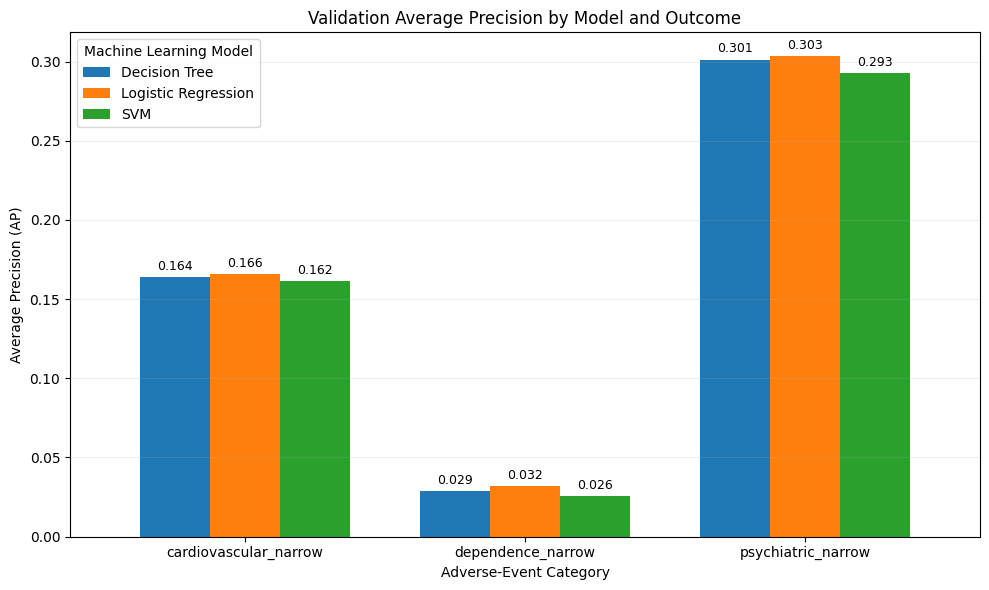

In [ ]:
# @title
ap_results = validation_results.pivot(
    index="Outcome",
    columns="Model",
    values="Average Precision"
)

fig, ax = plt.subplots(figsize=(10, 6))

ap_results.plot(
    kind="bar",
    ax=ax,
    width=0.75
)

ax.set_title("Validation Average Precision by Model and Outcome")
ax.set_xlabel("Adverse-Event Category")
ax.set_ylabel("Average Precision (AP)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title="Machine Learning Model")
ax.grid(axis="y", alpha=0.2)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)

plt.tight_layout()

plt.savefig(
    "figure1_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


As illustrated in Figure 1, Logistic Regression achieved the highest average precision across all three adverse event categories, with scores of 0.1660 for cardiovascular events, 0.3034 for psychiatric events, and 0.0319 for dependence related events. Although the differences between models were relatively small for cardiovascular and psychiatric outcomes, Logistic Regression consistently achieved the highest validation AP.

As stated in the analysis report, there are substantial amounts of missing values among age groups, which may have limited the models’ performance. Although the Average Precision scores were relatively low, Logistic Regression consistently performed better than SVM and Decision Tree. Based on these results, Logistic Regression was selected for the final evaluation of all three adverse-event outcomes.

### Logistics Regression Model Evaluation
After selecting Logistic Regression, the models were tested using data that was not used during training or model selection to evaluate their performance. Precision, recall, F1-score, and ROC-AUC were used to evaluate the models across cardiovascular, psychiatric, and dependence related adverse event outcomes.

**Figure 2. Heatmap of Logistic Regression Test Performance Across Adverse Event Categories**

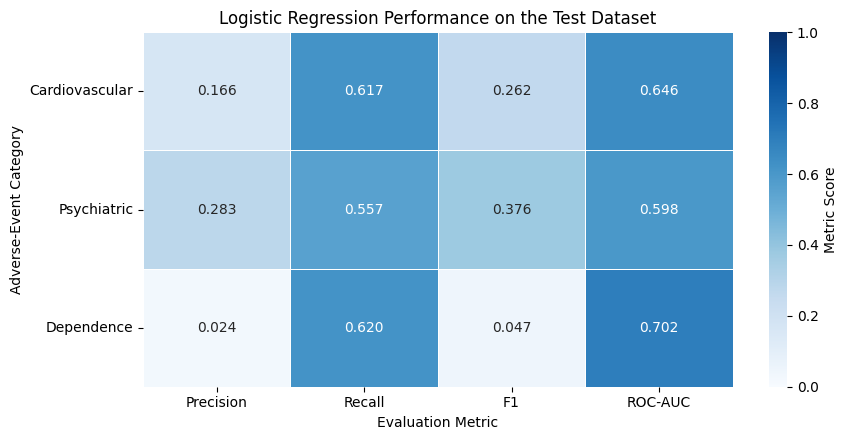

In [ ]:
# @title
lr_test = test_results_df[
    test_results_df["Model"] == "Logistic Regression"
].copy()

lr_test["Outcome"] = lr_test["Outcome"].replace({
    "cardiovascular_narrow": "Cardiovascular",
    "psychiatric_narrow": "Psychiatric",
    "dependence_narrow": "Dependence"
})

metrics = ["Precision", "Recall", "F1", "ROC-AUC"]

heatmap_data = lr_test.set_index("Outcome")[metrics].reindex([
    "Cardiovascular", "Psychiatric", "Dependence"
])

fig, ax = plt.subplots(figsize=(9, 4.5))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Metric Score"},
    ax=ax
)

ax.set_title("Logistic Regression Performance on the Test Dataset")
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Adverse-Event Category")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)

plt.tight_layout()

# Save the figure for Word
plt.savefig(
    "figure2_logistic_regression_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Figure 2 presents the evaluation metrics for the selected Logistic Regression models. The heatmap uses color intensity to distinguish higher and lower metric scores, allowing performance differences to be compared across adverse-event categories.

The results show the differences between recall and precision, particularly for dependence-related events. Although the models can identify a portion of positive cases, their precision indicates that many positive predictions are incorrect, especially for less frequent reported outcomes.

**Adjusted Logistic Regression Results**

Adjusted logistic regression was used to examine the association between medication class and adverse-event reporting while accounting for patient age and sex. Figure 3 presents the adjusted odds ratios and 95% confidence intervals for cardiovascular, psychiatric, and dependence-related adverse events, comparing stimulant medications with nonstimulant medications.

**Figure 3. Adjusted Odds Ratios for Stimulant Medications Compared with Nonstimulant Medications**

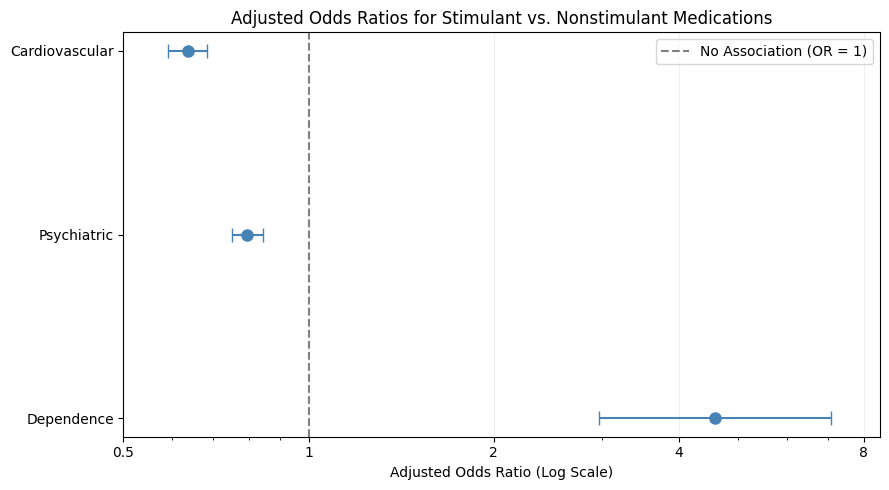

In [ ]:
# @title

categories = ["Cardiovascular", "Psychiatric", "Dependence"]
odds_ratios = np.array([0.6360, 0.7944, 4.5868])
ci_lower = np.array([0.5906, 0.7497, 2.9702])
ci_upper = np.array([0.6848, 0.8417, 7.0831])

errors = np.vstack([
    odds_ratios - ci_lower,
    ci_upper - odds_ratios
])

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(categories))

ax.errorbar(
    odds_ratios,
    y,
    xerr=errors,
    fmt="o",
    color="steelblue",
    ecolor="steelblue",
    capsize=5,
    markersize=8
)

ax.axvline(1, color="gray", linestyle="--", label="No Association (OR = 1)")

ax.set_yticks(y)
ax.set_yticklabels(categories)
ax.invert_yaxis()
ax.set_xscale("log")

ax.set_xlim(0.5, 8.5)

ax.xaxis.set_major_locator(FixedLocator([0.5, 1, 2, 4, 8]))
ax.xaxis.set_major_formatter(
    FixedFormatter(["0.5", "1", "2", "4", "8"])
)

ax.set_xlabel("Adjusted Odds Ratio (Log Scale)")
ax.set_title("Adjusted Odds Ratios for Stimulant vs. Nonstimulant Medications")
ax.grid(axis="x", alpha=0.2)
ax.legend()

plt.tight_layout()

plt.savefig(
    "figure3_adjusted_odds_ratios.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


The results show that stimulant medications were associated with lower odds of cardiovascular (OR = 0.636) and psychiatric (OR = 0.794) adverse-event reporting compared with nonstimulant medications. However, stimulant medications were associated with higher odds of dependence-related reporting (OR = 4.587).

All three confidence intervals exclude an odds ratio of 1, indicating statistically significant associations in this analysis.

**Adjusted Associations by Patient Age and Sex**

To further examine the relationship between patient demographics and adverse-event reporting, adjusted odds ratios were calculated for age and sex using logistic regression. Figure 4 presents these associations across cardiovascular, psychiatric, and dependence-related adverse-event categories. Patients aged 18-25 and female patients were used as the reference groups for age and sex, respectively.

**Figure 4. Adjusted Odds Ratios for Patient Age and Sex Across Adverse-Event Categories**

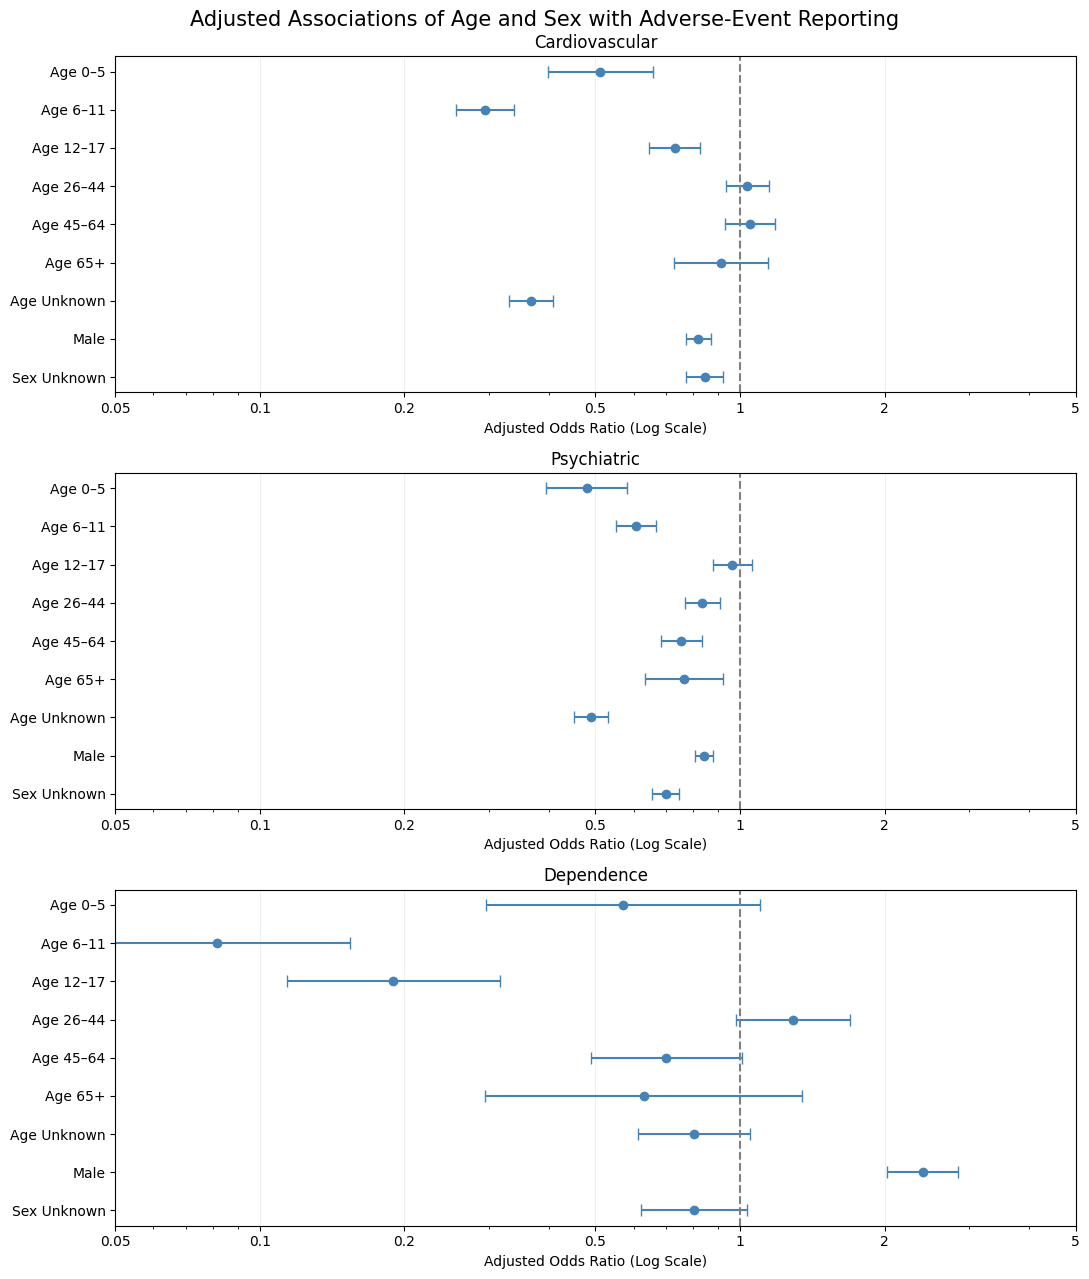

In [ ]:
# @title
variable_labels = {
    "age_band_fine_0_5": "Age 0–5",
    "age_band_fine_6_11": "Age 6–11",
    "age_band_fine_12_17": "Age 12–17",
    "age_band_fine_26_44": "Age 26–44",
    "age_band_fine_45_64": "Age 45–64",
    "age_band_fine_65_PLUS": "Age 65+",
    "age_band_fine_UNKNOWN": "Age Unknown",
    "sex_category_M": "Male",
    "sex_category_UNKNOWN": "Sex Unknown"
}

outcomes = {
    "cardiovascular_narrow": "Cardiovascular",
    "psychiatric_narrow": "Psychiatric",
    "dependence_narrow": "Dependence"
}

fig, axes = plt.subplots(3, 1, figsize=(11, 13))

for ax, (outcome, title) in zip(axes, outcomes.items()):

    results = odds_ratio_results[outcome].loc[
        list(variable_labels.keys())
    ]

    y = np.arange(len(results))
    odds = results["Odds Ratio"].to_numpy()
    lower = results["CI Lower"].to_numpy()
    upper = results["CI Upper"].to_numpy()

    errors = np.vstack([odds - lower, upper - odds])

    ax.errorbar(
        odds, y,
        xerr=errors,
        fmt="o",
        color="steelblue",
        ecolor="steelblue",
        capsize=4,
        markersize=6
    )

    ax.axvline(1, color="gray", linestyle="--")

    ax.set_yticks(y)
    ax.set_yticklabels(variable_labels.values())
    ax.invert_yaxis()

    ax.set_xscale("log")
    ax.set_xlim(0.05, 5)
    ticks = [0.05, 0.1, 0.2, 0.5, 1, 2, 5]
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(
        FixedFormatter([str(tick) for tick in ticks])
    )
    ax.xaxis.set_minor_formatter(NullFormatter())

    ax.set_title(title)
    ax.set_xlabel("Adjusted Odds Ratio (Log Scale)")
    ax.grid(axis="x", alpha=0.2)

fig.suptitle(
    "Adjusted Associations of Age and Sex with Adverse-Event Reporting",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "figure4_demographic_odds_ratios.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


The results show that several age groups were associated with differences in adverse-event reporting. For cardiovascular events, younger age groups generally had lower reporting odds compared with patients aged 18-25. Psychiatric reporting also varied across age groups, although not all differences were statistically significant. One interesting observation among the dependence-related results is that the adjusted odds ratios increased across the 6-11, 12-17, and 18-25 age groups. However, the 0-5 age group did not follow this pattern, and its association was not statistically significant.

Sex-related associations were also observed. Male patients had lower adjusted odds of cardiovascular and psychiatric adverse-event reporting compared with female patients, but approximately 2.4 times higher adjusted odds of dependence-related reporting.

These results demonstrate that patient demographics are associated with differences in adverse-event reporting patterns within the selected FAERS cases.

## Key Findings
The analysis identified differences in cardiovascular, psychiatric, and dependence-related advers- event reporting between stimulant and nonstimulant ADHD medications. Results showed that nonstimulant medications had higher cardiovascular (14.60%) and psychiatric (26.90%) reporting percentages compared with stimulant medications (10.12% and 21.67%, respectively). However stimulant medications had a higher dependence-relateed reporting percentage (1.48%) compared to nonstimulant medications (0.31%).

After accounting for patient age and sex, the adjusted Logistic Regression results supported these overall reporting patterns. Stimulant medications were associated with lower adjusted odds of cardiovascular (0.636) and psychiatric (0.794) adverse-event reporting compared with nonstimulant medications. In contrast, stimulant medications were associated with about 4.6 times higher adjusted odds of dependence-related reporting (4.587). All three medication-class associations were statistically significant.

Additional analysis showed that reporting patterns varied across patient age and sex categories. Cardiovascular reporting percentages were lower for stimulant medications across all age groups. Psychiatric reporting showed more variation, with stimulant medications having higher reporting percentages among patients aged 12-17 and 65 and over, despite the lower overall adjusted odds. Dependence-related reporting percentages were higher for stimulants across all age groups, with the highest percentage among stimulant reports occurring in patients aged 26-44 (2.87%). Both male and female patients showed higher dependence-related reporting percentages for stimulant medications, although the percentages were higher among males.

The machine learning results showed that Logistic Regression achieved the highest validation Average Precision over all three adverse-event categories compared with Decision Tree and SVM. However, overall predictive performance was limited, particularly for dependence-related events, where the final model achieved a precision of 0.024. These findings suggest that medication class, patient age, and sex provide some information about adverse-event reporting patterns, but these variables alone make the ability to make predictions very limited.

## Conclusion
The results of this analysis showed that adverse-event reporting patterns differed between stimulant and nonstimulant ADHD medications, even after accounting for patient age and sex. While the overall differences between medication classes were statistically significant, reporting percentages also varied across different age groups and between male and female patients. This shows why it is useful to examine patient demographics alongside medication class rather than looking at the overall results alone.

The machine learning models had limited success in predicting adverse-event reporting, particularly for dependence-related events. However, the descriptive analysis and adjusted logistic regression helped identify relationships between medication class, age, sex, and the reported adverse events. Although the results do not answer every question about these relationships, they provide a better understanding of the reporting patterns observed in the FAERS dataset.

## Limitations
One important limitation of this study is that the FAERS database relies on reports submitted by healthcare professionals, patients, and other sources. Not every adverse event is reported, and some reports may contain incomplete or inaccurate information. The database also does not provide the total number of patients taking each medication. Because of this, the results cannot tell us how likely a patient is to experience an adverse event or whether a particular medication caused it.

Another limitation was the large amount of missing information for patient age and sex. Although these records were kept in the analysis under an UNKNOWN category, the missing information made it more difficult to fully examine reporting differences across demographic groups. The machine learning models were also affected by class imbalance, especially for dependence-related events, where relatively few cases were reported. Finally, while the analysis compared reporting percentages across age and sex groups, additional statistical testing would be needed to determine whether the relationship between medication class and adverse-event reporting differs significantly across these groups.